# Predicting Student Final Exam Grades
### Decision Tree Regression, Random Forests, and a Confusion Matrix

**Our question:** Can we predict a student's final mathematics grade using their earlier grades and study habits?

By the end, we will:
1. Load and explore a real dataset.
2. Train a **decision tree regressor** with `max_depth=3`.
3. Evaluate its predictions with **MAE, RMSE, and R²**.
4. Draw the tree and inspect **feature importance**.
5. Compare it with a **random forest**.
6. Build a separate **pass/fail classifier** so we can see a **confusion matrix**.

> **Important:** Predicting an exact grade (e.g., 14.2/20) is **regression**. Predicting Pass or Fail is **classification**. A confusion matrix is for classification, not numeric regression.

**Dataset:** UCI [Student Performance](https://archive.ics.uci.edu/dataset/320/student+performance), mathematics course, 395 students. Grades range from **0 to 20**.

## 1. Import our tools

We only need a few standard Python data-science libraries. If something is missing, install it in a notebook cell with:

`%pip install pandas numpy matplotlib scikit-learn`

In [102]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, ConfusionMatrixDisplay
)

## 2. Load the real student data

The file uses **semicolons** (`;`) between columns, not commas.

- If you have `student-mat.csv` next to this notebook, it will use that file.
- Otherwise, it downloads the same dataset from a public GitHub mirror of the UCI data. **Internet is needed for the first download.**


In [103]:
# Direct CSV mirror of the UCI mathematics dataset.
url = "https://raw.githubusercontent.com/rupakc/UCI-Data-Analysis/master/Student%20Dataset/Student/student-mat.csv"

try:
    students = pd.read_csv("student-mat.csv", sep=";")
    print("Loaded student-mat.csv from this folder.")
except FileNotFoundError:
    students = pd.read_csv(url, sep=";")
    print("Downloaded the UCI student dataset.")

print("Students:", len(students))
students.head().T

Downloaded the UCI student dataset.
Students: 395


,0,1,2,3,4
school,GP,GP,GP,GP,GP
sex,F,F,F,F,F
age,18,17,15,15,16
address,U,U,U,U,U
famsize,GT3,GT3,LE3,GT3,GT3
Pstatus,A,T,T,T,T
Medu,4,1,1,4,3
Fedu,4,1,1,2,3
Mjob,at_home,at_home,at_home,health,other
Fjob,teacher,other,other,services,other


## 3. What are we predicting?

Our target is **`G3`**, the final mathematics grade (**0–20**).

Here is the distribution of those grades. Each bar shows how many students received a particular grade.

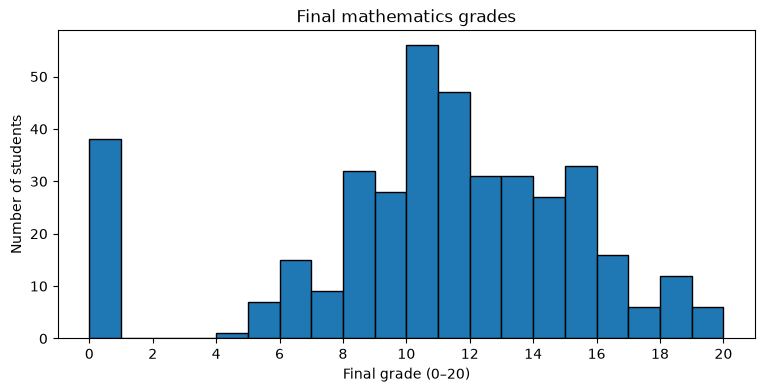

In [104]:
# See how the final grades are distributed.
plt.figure(figsize=(9, 4))
plt.hist(students["G3"], bins=20, edgecolor="black")
plt.title("Final mathematics grades")
plt.xlabel("Final grade (0–20)")
plt.ylabel("Number of students")
plt.xticks(range(0, 21, 2))
plt.show()

array([[<Axes: title={'center': 'final_grade_zero_to_onehundred'}>]],
      dtype=object)

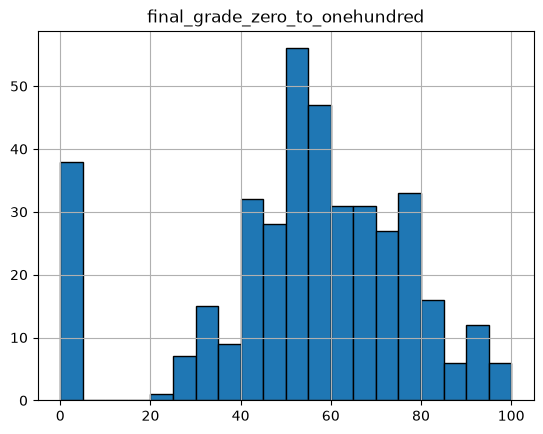

In [105]:
students["final_grade_zero_to_onehundred"] = students["G3"] * 5
students.hist(column="final_grade_zero_to_onehundred",bins=20, edgecolor="black")

## 4. Choose Features [link](https://archive.ics.uci.edu/dataset/320/student+performance) to data dictionary and meaning of every column.

We'll keep it simple with **7 numeric columns**:

| Column | Meaning |
|---|---|
| `G1` | First grading-period grade (0–20) |
| `G2` | Second grading-period grade (0–20) |
| `studytime` | Weekly study time (1 = least, 4 = most) |
| `failures` | Number of past class failures |
| `absences` | Number of school absences |
| `goout` | Frequency of going out with friends (1–5) |
| `freetime` | Amount of free time after school (1–5) |

We use `G1` and `G2` because they are available **before** the final grade. If we wanted to predict **at the start of the year**, we would need to remove them.

### All columns and information here. 

In [106]:
students.head().T

,0,1,2,3,4
school,GP,GP,GP,GP,GP
sex,F,F,F,F,F
age,18,17,15,15,16
address,U,U,U,U,U
famsize,GT3,GT3,LE3,GT3,GT3
Pstatus,A,T,T,T,T
Medu,4,1,1,4,3
Fedu,4,1,1,2,3
Mjob,at_home,at_home,at_home,health,other
Fjob,teacher,other,other,services,other


In [107]:
students.school.value_counts()

school
GP    349
MS     46
Name: count, dtype: int64

In [108]:
students.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3',
       'final_grade_zero_to_onehundred'],
      dtype='str')

In [109]:


# X = information we use to make predictions.
features = ["G1", "G2", "studytime", "failures", "absences", "goout", "freetime"]
# features = ["studytime", "failures", "absences", "goout", "freetime"]

X = students[features]

# y = the correct answer we want to predict.
y = students["G3"]

# Check for missing values before training.
print("Missing values per feature:")
print(X.isna().sum())

X.head()

Missing values per feature:
G1           0
G2           0
studytime    0
failures     0
absences     0
goout        0
freetime     0
dtype: int64


,G1,G2,studytime,failures,absences,goout,freetime
0,5,6,2,0,6,4,3
1,5,5,2,0,4,3,3
2,7,8,2,3,10,2,3
3,15,14,3,0,2,2,2
4,6,10,2,0,4,2,3


## 5. Split students into training and test sets

- **80% training:** Our model learns from these students.
- **20% testing:** Students the model hasn't seen while learning.

`random_state=42` makes the split repeatable, so everyone in class gets the same result.

In [110]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training students:", len(X_train))
print("Testing students:", len(X_test))

Training students: 316
Testing students: 79


## 6. Train our decision tree regressor

A **regression tree** predicts a *number*. Each split asks a yes/no question about one feature.

`max_depth=3` keeps the tree small enough to draw and explain.

In [111]:
# Make a small tree with at most 3 levels of questions.
tree = DecisionTreeRegressor(max_depth=3, random_state=42)

# The model learns only from the training students.
tree.fit(X_train, y_train)

# Predict final grades for unseen students.
tree_predictions = tree.predict(X_test)

# Look at some real grades vs. predicted grades.
comparison = pd.DataFrame({
    "Actual grade": y_test.to_numpy(),
    "Predicted grade": np.round(tree_predictions, 1)
})
comparison.head(10)

,Actual grade,Predicted grade
0,10,9.4
1,12,11.5
2,5,6.6
3,10,9.4
4,9,9.4
5,13,13.0
6,18,18.3
7,6,6.6
8,0,6.5
9,14,13.0


## 7. Draw the whole tree

**How to read it:**
- Start at the **top** node.
- If the condition is **True**, go **left**; otherwise go **right**.
- `samples` = number of *training* students in that node.
- `value` = average final grade of those training students. That's the prediction at a leaf!

The tree below has at most **3 splits from root to leaf**.

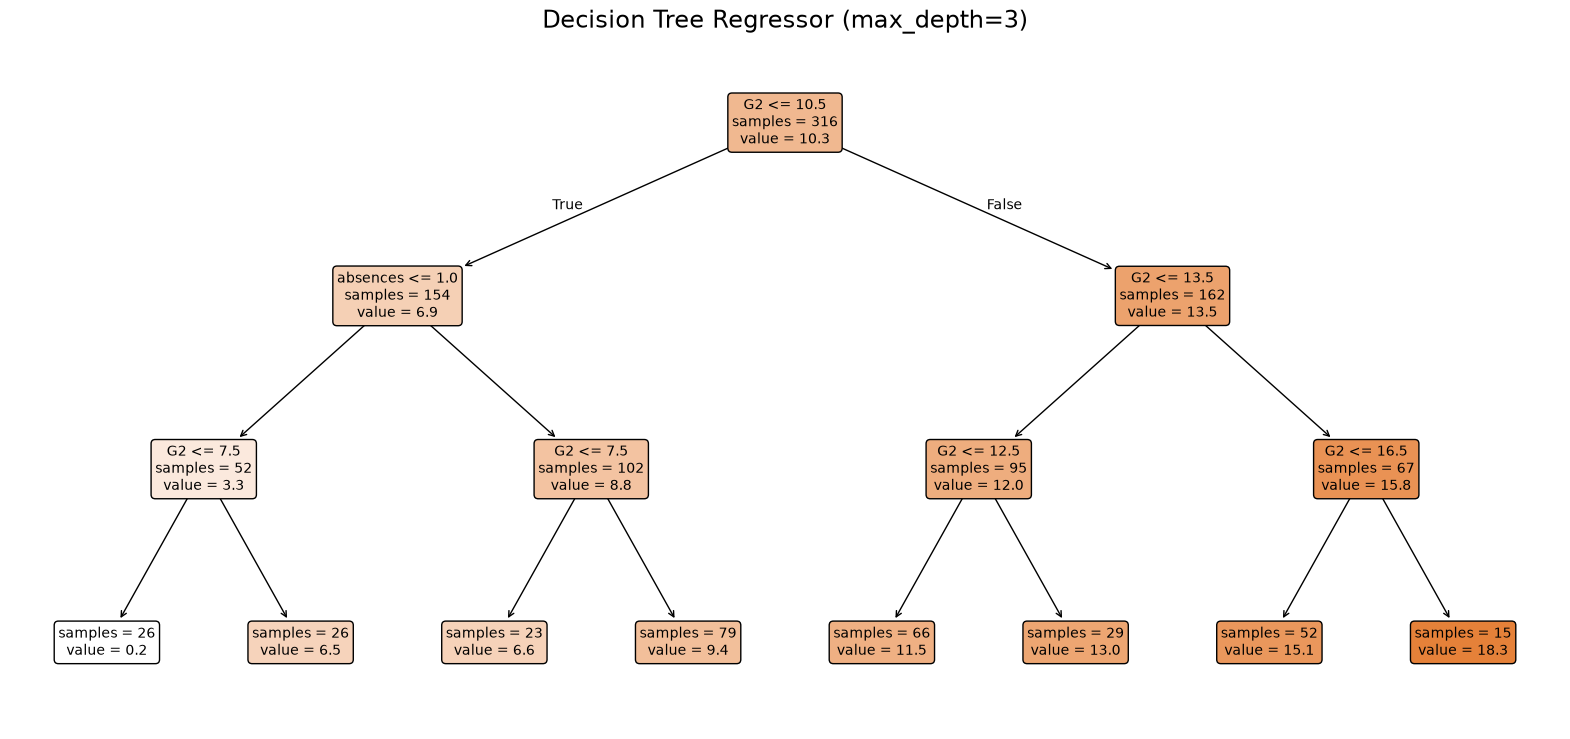

In [112]:
plt.figure(figsize=(20, 9))

plot_tree(
    tree,
    feature_names=features,
    filled=True,
    rounded=True,
    impurity=False,  # Hide the MSE formula to keep labels clean.
    precision=1,
    fontsize=10
)

plt.title("Decision Tree Regressor (max_depth=3)", fontsize=17)
plt.show()

## 8. Evaluate the predictions

We use **regression metrics**, because our output is a number.

- **MAE (mean absolute error):** On average, how many grade points are we off? **Lower is better.**
- **RMSE (root mean squared error):** Similar, but it penalizes big misses more. **Lower is better.**
- **R²:** How much better are we than always predicting the average grade? **1 is perfect; 0 is roughly equal to the average-grade baseline; negative is worse.**

Let's compare our tree with a very simple baseline that always predicts the average *training* grade.

In [113]:
# Baseline: always predict the average training grade.
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

# How wrong is our simple baseline?
baseline_mae = mean_absolute_error(y_test, baseline_predictions)

# How wrong is our decision tree?
tree_mae = mean_absolute_error(y_test, tree_predictions)
tree_rmse = np.sqrt(mean_squared_error(y_test, tree_predictions))
tree_r2 = r2_score(y_test, tree_predictions)

print(f"Baseline MAE: {baseline_mae:.2f} grade points")
print(f"Tree MAE:     {tree_mae:.2f} grade points")
print(f"Tree RMSE:    {tree_rmse:.2f} grade points")
print(f"Tree R²:      {tree_r2:.2f}")

Baseline MAE: 3.65 grade points
Tree MAE:     1.31 grade points
Tree RMSE:    2.17 grade points
Tree R²:      0.77


### Actual grade vs. predicted grade

If predictions were perfect, every dot would lie on the dashed diagonal line. Dots farther away mean bigger errors.

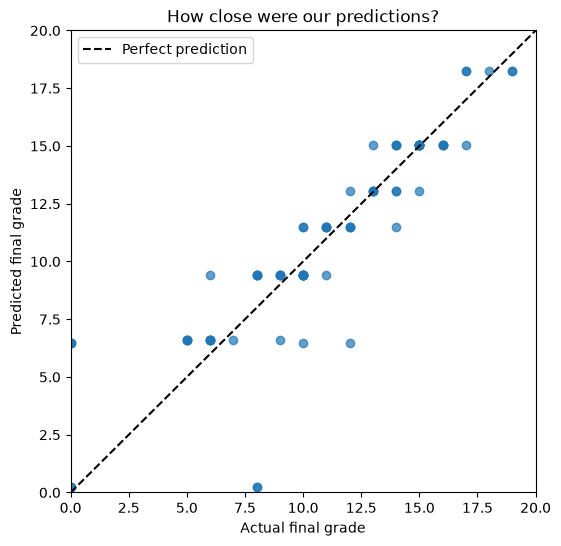

In [114]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, tree_predictions, alpha=0.7)
plt.plot([0, 20], [0, 20], "k--", label="Perfect prediction")
plt.xlim(0, 20)
plt.ylim(0, 20)
plt.xlabel("Actual final grade")
plt.ylabel("Predicted final grade")
plt.title("How close were our predictions?")
plt.legend()
plt.show()

## 9. Which features mattered most?

**Feature importance** measures how much each feature helped the tree reduce prediction error in its *training data*.

These scores add up to **1.0**. A high score means the tree used that feature to make useful splits. **It does not prove causation.**

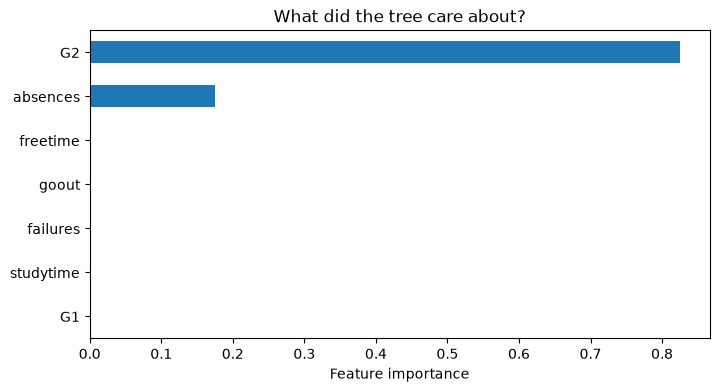

G2           0.825
absences     0.175
G1           0.000
failures     0.000
studytime    0.000
freetime     0.000
goout        0.000
dtype: float64


In [115]:
# Pair every feature name with its importance score.
importance = pd.Series(tree.feature_importances_, index=features)

# Put the largest importance at the top of the chart.
importance = importance.sort_values()

plt.figure(figsize=(8, 4))
importance.plot(kind="barh")
plt.xlabel("Feature importance")
plt.title("What did the tree care about?")
plt.show()

print(importance.sort_values(ascending=False).round(3))

## 10. Bonus: try a Random Forest Regressor

A **random forest** averages predictions from many different decision trees. It is often more accurate than one tiny tree, but harder to draw.

We'll try **100 trees** and compare the errors on the *same test students*.

In [116]:
# A forest of 100 trees, rather than one tree of depth 3.
forest = RandomForestRegressor(n_estimators=100, random_state=42)
forest.fit(X_train, y_train)
forest_predictions = forest.predict(X_test)

forest_mae = mean_absolute_error(y_test, forest_predictions)
forest_rmse = np.sqrt(mean_squared_error(y_test, forest_predictions))
forest_r2 = r2_score(y_test, forest_predictions)

# How wrong is our decision tree?
print(f"Baseline MAE: {baseline_mae:.2f} grade points")
print('/'*33)
print(f"Tree MAE:     {tree_mae:.2f} grade points")
print(f"Tree RMSE:    {tree_rmse:.2f} grade points")
print(f"Tree R²:      {tree_r2:.2f}")


print('/'*33)
print(f"Random forest MAE:  {forest_mae:.2f}")
print(f"Random forest RMSE: {forest_rmse:.2f}")
print(f"Random forest R²:   {forest_r2:.2f}")

Baseline MAE: 3.65 grade points
/////////////////////////////////
Tree MAE:     1.31 grade points
Tree RMSE:    2.17 grade points
Tree R²:      0.77
/////////////////////////////////
Random forest MAE:  1.13
Random forest RMSE: 1.71
Random forest R²:   0.86


## 11. Confusion matrix: a **different** problem (Pass vs. Fail)

A confusion matrix cannot directly evaluate predictions like **12.7/20**. It needs **categories**.

So let's create a **separate decision tree classifier**, also with `max_depth=3`:

- **Fail (0):** Final grade below 10.
- **Pass (1):** Final grade 10 or higher.

We use the *same features and the same train/test split*, but now train the model to predict **Pass or Fail**, not an exact grade.

# Okay.  So G2 is by far the most important factor to determining G3.  But thats obvious....  Tell me something more interesting. 
### Remove G1 and G2, and try using interesting features like "Walc" weekend alcohol consumption. "
### Full list of features [see the data dict](https://archive.ics.uci.edu/dataset/320/student+performance)

# Student that comes up with the MOST INTERESTING finding gets a FULL WEEK homework pass and letter of rec from me. 
Some interesting features:
* "absences" - number of school absences (numeric: from 0 to 93)
* "Walc" - weekend alcohol consumption (numeric: from 1 - very low to 5 - very high)
* "goout" - going out with friends (numeric: from 1 - very low to 5 - very high)
* "reason" - reason to choose this school (nominal: close to 'home', school 'reputation', 'course' preference or 'other')


---
# Homework: Something juicy about what influences final grade (G3)

Same data, but now predicting G3 **without G1 and G2**, using every other column.
New variable names (`hw_...`) so nothing from the class sections above gets overwritten.

## H1. Predict G3 without G1 and G2
- Drop the three grades, plus `final_grade_zero_to_onehundred` (it's just G3 × 5, so keeping it would leak the answer).
- `pd.get_dummies` turns text columns (`school`, `sex`, `reason`, `Mjob`, yes/no columns...) into 0/1 columns sklearn can use.
- Same split settings as class: 80/20, `random_state=42`.

In [126]:
hw_X = pd.get_dummies(
    students.drop(columns=["G1", "G2", "G3", "final_grade_zero_to_onehundred"], errors="ignore"),
    drop_first=True,
)
hw_y = students["G3"]

hw_X_train, hw_X_test, hw_y_train, hw_y_test = train_test_split(
    hw_X, hw_y, test_size=0.20, random_state=42
)
print("Features:", hw_X.shape[1], "| Training students:", len(hw_X_train), "| Test students:", len(hw_X_test))

hw_baseline = DummyRegressor(strategy="mean").fit(hw_X_train, hw_y_train)
hw_tree = DecisionTreeRegressor(max_depth=3, random_state=42).fit(hw_X_train, hw_y_train)
hw_forest = RandomForestRegressor(n_estimators=100, random_state=42).fit(hw_X_train, hw_y_train)

for name, model in [("Baseline", hw_baseline), ("Tree (depth 3)", hw_tree), ("Random forest", hw_forest)]:
    pred = model.predict(hw_X_test)
    mae = mean_absolute_error(hw_y_test, pred)
    rmse = np.sqrt(mean_squared_error(hw_y_test, pred))
    r2 = r2_score(hw_y_test, pred)
    print(f"{name:15s} MAE: {mae:.2f}   RMSE: {rmse:.2f}   R²: {r2:.2f}")

Features: 39 | Training students: 316 | Test students: 79
Baseline        MAE: 3.65   RMSE: 4.55   R²: -0.01
Tree (depth 3)  MAE: 3.55   RMSE: 4.41   R²: 0.05
Random forest   MAE: 3.15   RMSE: 3.94   R²: 0.24


## H2. What did the models lean on?
Feature importance shows what the model **used** to make splits. It does **not** prove cause and effect.

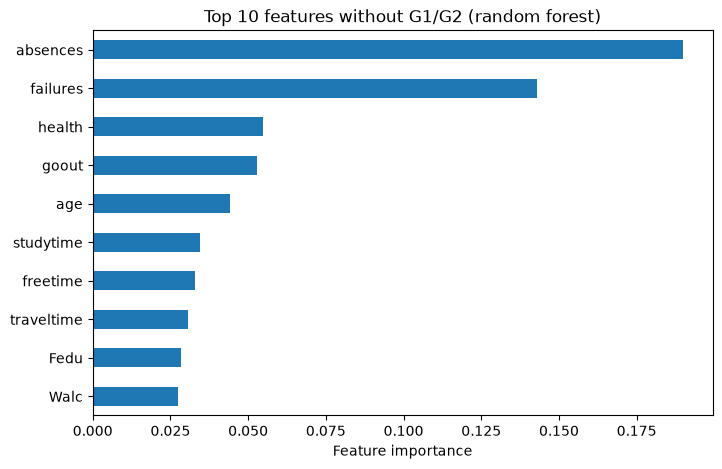

In [127]:
hw_importance = pd.Series(hw_forest.feature_importances_, index=hw_X.columns).sort_values()

hw_importance.tail(10).plot(kind="barh", figsize=(8, 5))
plt.xlabel("Feature importance")
plt.title("Top 10 features without G1/G2 (random forest)")
plt.show()

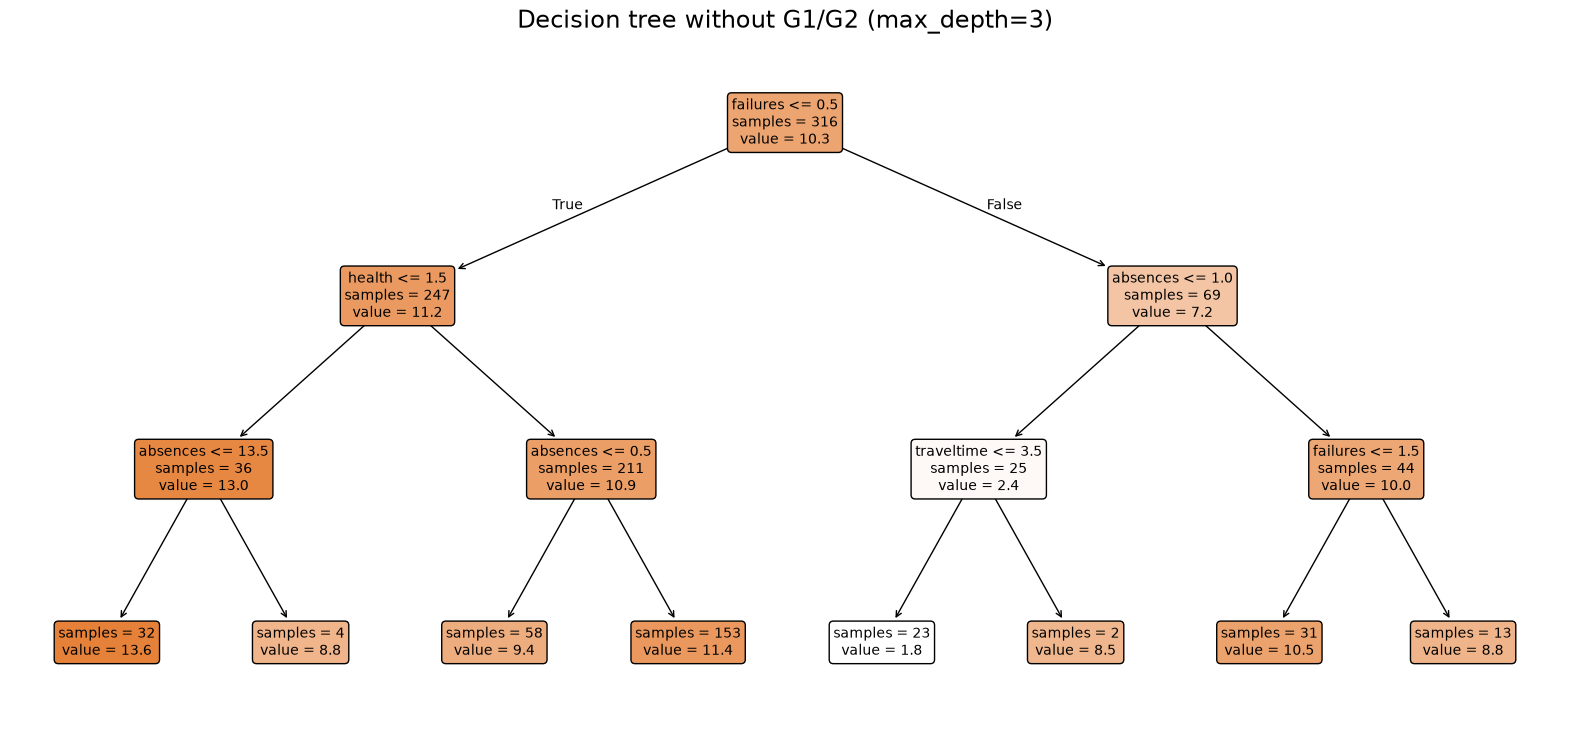

In [128]:
plt.figure(figsize=(20, 9))
plot_tree(hw_tree, feature_names=list(hw_X.columns), filled=True, rounded=True,
          impurity=False, precision=1, fontsize=10)
plt.title("Decision tree without G1/G2 (max_depth=3)", fontsize=17)
plt.show()

## H3. Exploration tool: `grade_by()`
For any column: each group's **number of students**, **average final grade**, and **pass rate** (share with G3 ≥ 10).
Check the `students` column before trusting a pattern: a group of 5 students proves nothing.

In [129]:
def grade_by(key):
    return (students.groupby(key, observed=True)["G3"]
            .agg(students="count", avg_grade="mean", pass_rate=lambda g: (g >= 10).mean())
            .round(2))

display(grade_by("Walc"))
display(grade_by("goout"))
display(grade_by("failures"))
display(grade_by(pd.cut(students["absences"], [-1, 0, 5, 10, 20, 100])))  # absences in ranges

,students,avg_grade,pass_rate
Walc,,,
1,151,10.74,0.67
2,85,10.08,0.71
3,80,10.72,0.69
4,51,9.69,0.61
5,28,10.14,0.64


,students,avg_grade,pass_rate
goout,,,
1,23,9.87,0.74
2,103,11.19,0.77
3,130,10.96,0.72
4,86,9.65,0.56
5,53,9.04,0.53


,students,avg_grade,pass_rate
failures,,,
0,312,11.25,0.75
1,50,8.12,0.48
2,17,6.24,0.18
3,16,5.69,0.25


,students,avg_grade,pass_rate
absences,,,
"(-1, 0]",115,8.44,0.57
"(0, 5]",134,11.65,0.78
"(5, 10]",80,11.40,0.74
"(10, 20]",51,10.12,0.57
"(20, 100]",15,10.27,0.47


## H4. My exploration
Try `grade_by()` on other columns from the [data dictionary](https://archive.ics.uci.edu/dataset/320/student+performance).
Split by two columns at once with a list, e.g. `grade_by(["sex", "Walc"])`.

In [130]:
# H4. Hypothesis: do a student's circumstances predict G3 better than their own habits?
# Group A = things the student does. Group B = things about their family, school and home.
# Left out on purpose: G1, G2, failures, higher (and any column not listed in either group).
hw_habit_cols = ["Walc", "Dalc", "goout", "freetime", "studytime", "absences", "romantic", "activities"]
hw_circumstance_cols = ["Medu", "Fedu", "Mjob", "Fjob", "famrel", "famsup", "schoolsup", "paid",
                        "Pstatus", "guardian", "internet", "address", "traveltime", "school"]

def hw_encoded(original_cols):
    """The hw_X columns that came from these original columns.
    get_dummies renamed text columns (e.g. romantic -> romantic_yes, Mjob -> Mjob_health, ...)."""
    return [c for c in hw_X.columns
            if c in original_cols or any(c.startswith(col + "_") for col in original_cols)]

hw_groups = {
    "A: habits": hw_encoded(hw_habit_cols),
    "B: circumstances": hw_encoded(hw_circumstance_cols),
}
for name, cols in hw_groups.items():
    print(f"{name}: {len(cols)} model columns -> {cols}")

def hw_scores(name, n_cols, pred):
    return {"Model": name, "Model columns": n_cols,
            "MAE": mean_absolute_error(hw_y_test, pred),
            "RMSE": np.sqrt(mean_squared_error(hw_y_test, pred)),
            "R²": r2_score(hw_y_test, pred)}

# Same students as H1: we only pick columns from hw_X_train / hw_X_test, we never re-split.
hw_rows = [hw_scores("H1 baseline (always guess the mean)", 0, hw_baseline.predict(hw_X_test))]
hw_group_forests = {}
for name, cols in hw_groups.items():
    rf = RandomForestRegressor(n_estimators=100, random_state=42).fit(hw_X_train[cols], hw_y_train)
    hw_group_forests[name] = rf
    hw_rows.append(hw_scores(f"Forest, group {name}", len(cols), rf.predict(hw_X_test[cols])))

hw_group_results = pd.DataFrame(hw_rows).round(2)
hw_group_results

A: habits: 8 model columns -> ['studytime', 'freetime', 'goout', 'Dalc', 'Walc', 'absences', 'activities_yes', 'romantic_yes']
B: circumstances: 21 model columns -> ['Medu', 'Fedu', 'traveltime', 'famrel', 'school_MS', 'address_U', 'Pstatus_T', 'Mjob_health', 'Mjob_other', 'Mjob_services', 'Mjob_teacher', 'Fjob_health', 'Fjob_other', 'Fjob_services', 'Fjob_teacher', 'guardian_mother', 'guardian_other', 'schoolsup_yes', 'famsup_yes', 'paid_yes', 'internet_yes']


,Model,Model columns,MAE,RMSE,R²
0,H1 baseline (always guess the mean),0,3.65,4.55,-0.01
1,"Forest, group A: habits",8,3.85,4.93,-0.19
2,"Forest, group B: circumstances",21,3.91,4.83,-0.14


In [131]:
# H4 (continued). Group averages for four circumstance columns.
# Check the "students" column first: small groups can show big differences by chance.
for col in ["schoolsup", "famsup", "famrel", "Medu"]:
    print(f"\n=== {col} ===")
    display(grade_by(col))


=== schoolsup ===


,students,avg_grade,pass_rate
schoolsup,,,
no,344,10.56,0.69
yes,51,9.43,0.55



=== famsup ===


,students,avg_grade,pass_rate
famsup,,,
no,153,10.64,0.71
yes,242,10.27,0.65



=== famrel ===


,students,avg_grade,pass_rate
famrel,,,
1,8,10.62,0.75
2,18,9.89,0.61
3,68,10.04,0.62
4,195,10.36,0.67
5,106,10.83,0.71



=== Medu ===


,students,avg_grade,pass_rate
Medu,,,
0,3,13.00,0.67
1,59,8.68,0.58
2,103,9.73,0.65
3,99,10.30,0.65
4,131,11.76,0.75


In [132]:
# H4 (continued). Who are the G3 = 0 students? Compare them with everyone else.
hw_zero_label = (students["G3"] == 0).map({True: "G3 = 0", False: "G3 > 0"})
print(f"G3 = 0 students: {(students['G3'] == 0).sum()} of {len(students)}")

# Count, mean, median, min and max of each column, per group (.T puts the two groups side by side).
display(students.groupby(hw_zero_label)[["absences", "failures", "G1", "G2"]]
        .agg(["count", "mean", "median", "min", "max"]).round(2).T)

# Share of each group with: no absences, a G2 of 0, at least one past failure.
display(pd.DataFrame({
    "absences == 0": (students["absences"] == 0).groupby(hw_zero_label).mean(),
    "G2 == 0":       (students["G2"] == 0).groupby(hw_zero_label).mean(),
    "failures >= 1": (students["failures"] >= 1).groupby(hw_zero_label).mean(),
}).round(2))

G3 = 0 students: 38 of 395


G3               G3 = 0  G3 > 0
absences count    38.00  357.00
         mean      0.00    6.32
         median    0.00    4.00
         min       0.00    0.00
         max       0.00   75.00
failures count    38.00  357.00
         mean      0.92    0.27
         median    1.00    0.00
         min       0.00    0.00
         max       3.00    3.00
G1       count    38.00  357.00
         mean      7.53   11.27
         median    7.00   11.00
         min       4.00    3.00
         max      12.00   19.00
G2       count    38.00  357.00
         mean      4.66   11.36
         median    5.00   11.00
         min       0.00    5.00
         max      10.00   19.00

,absences == 0,G2 == 0,failures >= 1
G3,,,
G3 = 0,1.00,0.34,0.53
G3 > 0,0.22,0.00,0.18


In [133]:
# H4 (continued). 5-fold cross-validation: each student is in a test fold exactly once,
# so the scores don't depend on H1's single 79-student test set.
from sklearn.model_selection import KFold, cross_validate

# Groups A and B from the H4 cell above, plus Group C (columns in neither) and the full H1 column set.
hw_cv_groups = {**hw_groups,
                "C: neither group": hw_encoded(["failures", "higher", "health", "age",
                                                "sex", "reason", "famsize", "nursery"]),
                "Full H1 (all)": list(hw_X.columns)}

# shuffle=True because the CSV is sorted by school (all GP rows, then all MS).
# One KFold object, so every model is tested on the same 5 folds.
hw_kfold = KFold(n_splits=5, shuffle=True, random_state=42)

def hw_cv_summary(rows):
    """5-fold CV on the students where `rows` is True. One summary row per model."""
    X, y = hw_X[rows], hw_y[rows]
    models = [("Baseline (mean)", DummyRegressor(strategy="mean"), [])]
    models += [(f"Forest {name}", RandomForestRegressor(n_estimators=100, random_state=42), cols)
               for name, cols in hw_cv_groups.items()]
    out = []
    for name, model, cols in models:
        cv = cross_validate(model, X[cols or list(X.columns)], y, cv=hw_kfold,
                            scoring=["r2", "neg_mean_absolute_error"])
        r2, mae = cv["test_r2"], -cv["test_neg_mean_absolute_error"]  # sklearn reports MAE as a negative
        out.append({"Model": name, "Cols": len(cols),
                    "R² mean": r2.mean(), "R² std": r2.std(), "R² min": r2.min(), "R² max": r2.max(),
                    "MAE mean": mae.mean(), "MAE std": mae.std(), "MAE min": mae.min(), "MAE max": mae.max()})
    return pd.DataFrame(out).round(2)

print("All students:")
display(hw_cv_summary(hw_y >= 0))   # every student
print("G3 = 0 students excluded:")
display(hw_cv_summary(hw_y > 0))

All students:


,Model,Cols,R² mean,R² std,R² min,R² max,MAE mean,MAE std,MAE min,MAE max
0,Baseline (mean),0,-0.01,0.01,-0.02,-0.00,3.43,0.34,3.04,3.89
1,Forest A: habits,8,-0.05,0.13,-0.20,0.19,3.55,0.25,3.14,3.93
2,Forest B: circumstances,21,-0.19,0.10,-0.34,-0.02,3.74,0.28,3.39,4.08
3,Forest C: neither group,10,-0.11,0.11,-0.26,0.03,3.71,0.19,3.54,4.00
4,Forest Full H1 (all),39,0.29,0.04,0.23,0.34,2.89,0.21,2.60,3.16


G3 = 0 students excluded:


,Model,Cols,R² mean,R² std,R² min,R² max,MAE mean,MAE std,MAE min,MAE max
0,Baseline (mean),0,-0.00,0.00,-0.01,-0.00,2.63,0.11,2.47,2.77
1,Forest A: habits,8,-0.02,0.13,-0.23,0.12,2.64,0.06,2.54,2.71
2,Forest B: circumstances,21,-0.01,0.14,-0.26,0.12,2.56,0.14,2.34,2.77
3,Forest C: neither group,10,-0.11,0.17,-0.37,0.08,2.70,0.33,2.23,3.17
4,Forest Full H1 (all),39,0.17,0.05,0.10,0.24,2.35,0.10,2.21,2.47


In [134]:
# H4 (continued). Is G3 = 0 more common among romantic = yes students?
# Chi-square test of independence on a romantic × (G3 = 0 vs G3 > 0) count table.
from scipy.stats import chi2_contingency

for label, df in [("All students", students),
                  ("Girls", students[students["sex"] == "F"]),
                  ("Boys",  students[students["sex"] == "M"])]:
    counts = pd.crosstab(df["romantic"], (df["G3"] == 0).map({True: "G3 = 0", False: "G3 > 0"}))
    chi2, p, dof, expected = chi2_contingency(counts)   # default: Yates correction on a 2x2 table
    counts["total"] = counts.sum(axis=1)
    counts["share G3 = 0"] = (counts["G3 = 0"] / counts["total"]).round(3)
    print(f"\n=== {label} ===")
    display(counts)
    print(f"chi-square = {chi2:.2f}, dof = {dof}, p = {p:.4f}, smallest expected count = {expected.min():.1f}")
# Boys: the smallest expected count is 4.3 (below 5), so the boys' chi-square p-value is unreliable.

# Girls only: G3 = 0 count and share by age (19+ merged into one group) and romantic.
hw_girls = students[students["sex"] == "F"]
hw_girl_age = hw_girls["age"].clip(upper=19).astype(str).replace("19", "19+").rename("age")
hw_girls_zero = (hw_girls["G3"].eq(0)                     # True where G3 = 0
                 .groupby([hw_girl_age, hw_girls["romantic"]])
                 .agg(students="count", g3_zero_count="sum", share_g3_zero="mean")
                 .round(3))
hw_girls_zero["flag"] = np.where(hw_girls_zero["students"] < 20, "< 20 students", "")
display(hw_girls_zero)


=== All students ===


G3,G3 = 0,G3 > 0,total,share G3 = 0
romantic,,,,
no,18,245,263,0.068
yes,20,112,132,0.152


chi-square = 6.05, dof = 1, p = 0.0139, smallest expected count = 12.7

=== Girls ===


G3,G3 = 0,G3 > 0,total,share G3 = 0
romantic,,,,
no,8,121,129,0.062
yes,15,64,79,0.190


chi-square = 6.90, dof = 1, p = 0.0086, smallest expected count = 8.7

=== Boys ===


G3,G3 = 0,G3 > 0,total,share G3 = 0
romantic,,,,
no,10,124,134,0.075
yes,5,48,53,0.094


chi-square = 0.02, dof = 1, p = 0.8819, smallest expected count = 4.3


students  g3_zero_count  share_g3_zero           flag
age romantic                                                       
15  no              28              1          0.036               
    yes             10              3          0.300  < 20 students
16  no              39              1          0.026               
    yes             15              2          0.133  < 20 students
17  no              33              0          0.000               
    yes             25              5          0.200               
18  no              22              4          0.182               
    yes             21              4          0.190               
19+ no               7              2          0.286  < 20 students
    yes              8              1          0.125  < 20 students

## H5. My finding
I looked into the data more and saw that there were students with “perfect attendance” but their final grades were 0. All 38 students who got a 0 had exactly 0 absences. At first I had no idea why no absences would lead to this, so I looked into it more. It sort of looked like they dropped out and the school just stopped recording their attendance.

So I tried looking deeper into that and played around with other factors. One that was interesting was romance, essentially if the students were in a relationship. For the students that stayed, it didn’t seem to change much. But among the students who got a 0, girls in relationships were the biggest group: 15 of the 38, even though they’re only about 20% of all students. 19% of girls in relationships got a 0, compared with 6% of single girls, and the p-value (0.009) supports that this gap isn’t just chance.

So I did more research and found articles and studies about this. In [this study from the University of Georgia](https://news.uga.edu/?p=9903), which followed 624 students from 6th to 12th grade, students who started dating early in middle school were four times more likely to drop out of high school than students who dated less. And according to [CDC survey data from 2021](https://edweek.org/leadership/teen-dating-violence-has-lifelong-consequences-heres-how-schools-can-help/2023/05), girls in the US deal with dating violence a lot more than boys: 15.3% of high school girls reported sexual dating violence in the past year, compared with 4% of boys. Also, the dataset was from schools in Portugal, and in [the paper behind it](https://www.stat.cmu.edu/~brian/valerie/617-2022/617-2021/project01/UCI%20ML%20data%20sets/student%20performance/student.pdf) by Cortez and Silva (2008), I found that dropping out was a big problem at the time: in 2006, 40% of 18 to 24 year olds in Portugal had left school early, compared with 15% across the EU. So maybe there should be more guidance for girls on things like this, especially girls around 15 to 17, since that's where the gap showed up the most. Counselors could check in with students who are going through relationship stuff, not just the ones with bad grades or a lot of absences. The tricky part is that the students who left looked like they had perfect attendance on paper because they had no absences recorded, so schools should probably mark when a student leaves instead of just leaving it blank, so they can catch it.